In [1]:
%pip install -q tensorflow scipy scikit-learn pandas matplotlib seaborn

In [1]:
import os
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from google.colab import files

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("SciPy:", scipy.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
SciPy: 1.16.3
GPU available: True


In [5]:
uploaded = files.upload()

csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

print("Uploaded files:", csv_files)

if not csv_files:
    raise ValueError("Please upload at least one CSV file.")

Saving DailyDelhiClimateTrain - Copy.csv to DailyDelhiClimateTrain - Copy.csv
Saving DailyDelhiClimateTest - Copy.csv to DailyDelhiClimateTest - Copy.csv
Uploaded files: ['DailyDelhiClimateTrain - Copy.csv', 'DailyDelhiClimateTest - Copy.csv']


In [6]:
train_df = pd.read_csv("DailyDelhiClimateTrain.csv")
test_df = pd.read_csv("DailyDelhiClimateTest.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

df = pd.concat([train_df, test_df], ignore_index=True)

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"])
df = df.sort_values("date")
df = df.drop_duplicates(subset=["date"], keep="first")
df = df.reset_index(drop=True)

print("Combined dataset:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

display(df.head())

Training shape: (1462, 5)
Testing shape: (114, 5)
Combined dataset: (1575, 5)
Date range: 2013-01-01 00:00:00 to 2017-04-24 00:00:00


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [7]:
df.columns = [c.strip().lower() for c in df.columns]

target_col = "meantemp"

if target_col not in df.columns:
    raise ValueError(f"Temperature column not found: {df.columns.tolist()}")

candidate_features = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

feature_cols = [
    c for c in candidate_features
    if c in df.columns
]

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[feature_cols] = df[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

df[feature_cols] = df[feature_cols].interpolate(
    method="linear",
    limit=3,
    limit_area="inside"
)

df = df.dropna(subset=feature_cols).reset_index(drop=True)

# Confirm consecutive dates
gaps = df["date"].diff().dt.days

print("Features:", feature_cols)
print("Usable records:", len(df))
print("Missing values:\n", df[feature_cols].isna().sum())
print("Date gaps greater than one day:", (gaps > 1).sum())

if len(df) < 1000:
    raise ValueError("At least 1,000 usable daily records are required.")

if (gaps.dropna() != 1).any():
    raise ValueError(
        "Select a continuous segment of daily records before training."
    )

display(df.head())

Features: ['meantemp', 'humidity', 'wind_speed', 'meanpressure']
Usable records: 1575
Missing values:
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64
Date gaps greater than one day: 0


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


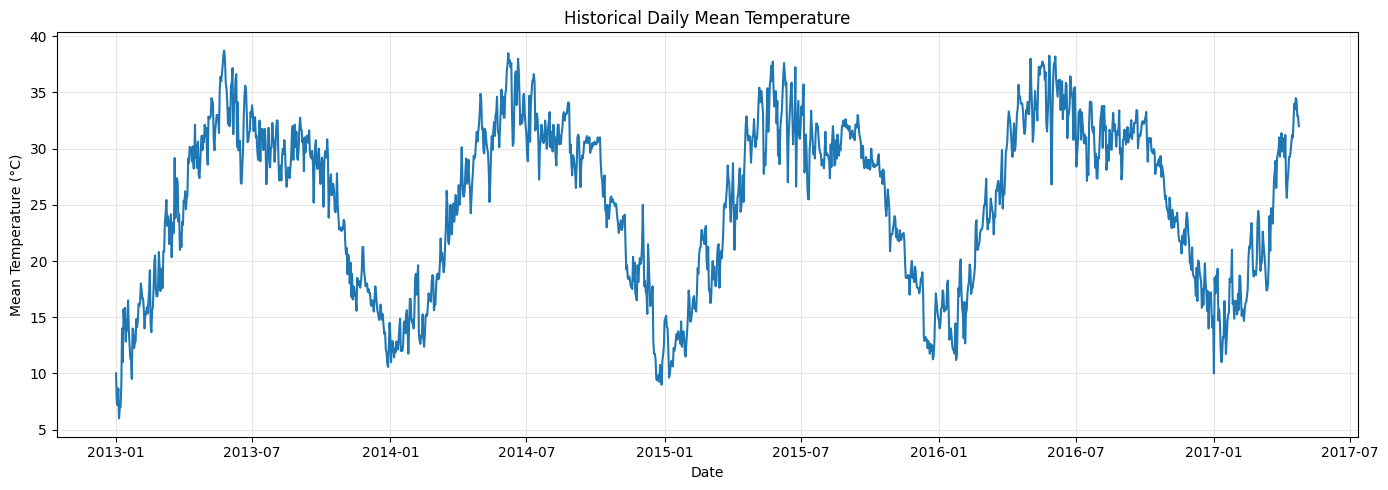

          meantemp     humidity  wind_speed  meanpressure
count  1575.000000  1575.000000  1575.00000   1575.000000
mean     25.227828    60.429087     6.90190   1011.197364
std       7.343597    16.973286     4.51094    173.648628
min       6.000000    13.428571     0.00000     -3.041667
25%      18.516667    49.750000     3.70000   1001.875000
50%      27.166667    62.380952     6.37000   1009.111111
75%      31.142857    72.125000     9.26250   1015.200000
max      38.714286   100.000000    42.22000   7679.333333


In [8]:
plt.figure(figsize=(14, 5))
plt.plot(df["date"], df["meantemp"])
plt.title("Historical Daily Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(df[feature_cols].describe())

In [9]:
LOOKBACK = 14

values = df[feature_cols].to_numpy(dtype=np.float32)
dates = df["date"].to_numpy()

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

scaler = StandardScaler()
scaler.fit(values[:train_end])

scaled_values = scaler.transform(values).astype(np.float32)
target_idx = feature_cols.index(target_col)

print("Training records:", train_end)
print("Validation records:", val_end - train_end)
print("Test records:", n - val_end)
print("Lookback days:", LOOKBACK)

Training records: 1102
Validation records: 236
Test records: 237
Lookback days: 14


In [10]:
X, y, positions = [], [], []

for i in range(LOOKBACK, n):
    X.append(scaled_values[i-LOOKBACK:i])
    y.append(scaled_values[i, target_idx])
    positions.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
positions = np.array(positions)

train_mask = positions < train_end
val_mask = (positions >= train_end) & (positions < val_end)
test_mask = positions >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

test_dates = df["date"].iloc[positions[test_mask]].reset_index(drop=True)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (1088, 14, 4)
X_val: (236, 14, 4)
X_test: (237, 14, 4)


In [11]:
model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, len(feature_cols))),

    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.20),

    layers.LSTM(32),
    layers.Dropout(0.20),

    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=5,
        factor=0.5,
        min_lr=1e-6
    ),

    keras.callbacks.ModelCheckpoint(
        "best_temperature_lstm.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    callbacks=callbacks,
    shuffle=False,
    verbose=1
)

Epoch 1/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.5222 - mae: 0.5681 - val_loss: 0.1627 - val_mae: 0.3217 - learning_rate: 0.0010
Epoch 2/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1452 - mae: 0.2970 - val_loss: 0.1383 - val_mae: 0.2974 - learning_rate: 0.0010
Epoch 3/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1251 - mae: 0.2771 - val_loss: 0.1260 - val_mae: 0.2834 - learning_rate: 0.0010
Epoch 4/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1044 - mae: 0.2558 - val_loss: 0.1204 - val_mae: 0.2724 - learning_rate: 0.0010
Epoch 5/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1060 - mae: 0.2550 - val_loss: 0.1190 - val_mae: 0.2683 - learning_rate: 0.0010
Epoch 6/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1026 - mae: 0.2508 - val_loss: 0.1426 - val_mae: 0.3019 - learning_rate: 0.0010
Epoch 7/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1191 - mae: 0.2693 - val_loss: 0.1249 - val_mae: 0.2781 - learning_rate: 0.0010
Epoch 8/

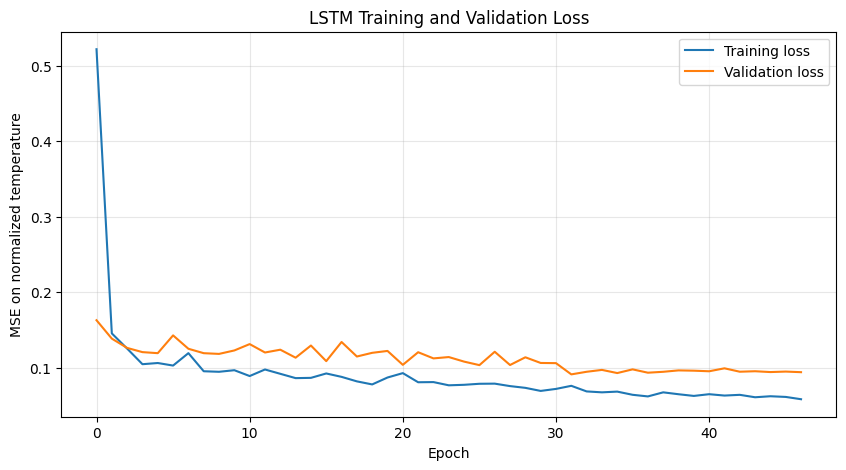

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE on normalized temperature")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
y_pred_scaled = model.predict(X_test, verbose=0).ravel()

target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]

y_actual = y_test * target_scale + target_mean
y_pred = y_pred_scaled * target_scale + target_mean

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mse = mean_squared_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

print(f"MAE:  {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"MSE:  {mse:.4f} °C²")
print(f"R²:   {r2:.4f}")

MAE:  1.8378 °C
RMSE: 2.2934 °C
MSE:  5.2598 °C²
R²:   0.8658


In [23]:
print("===== MODEL PERFORMANCE =====")
print(f"MAE: {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"R² Score: {r2:.4f}")
print(f"R² Percentage: {r2 * 100:.2f}%")

===== MODEL PERFORMANCE =====
MAE: 1.8378 °C
RMSE: 2.2934 °C
R² Score: 0.8658
R² Percentage: 86.58%


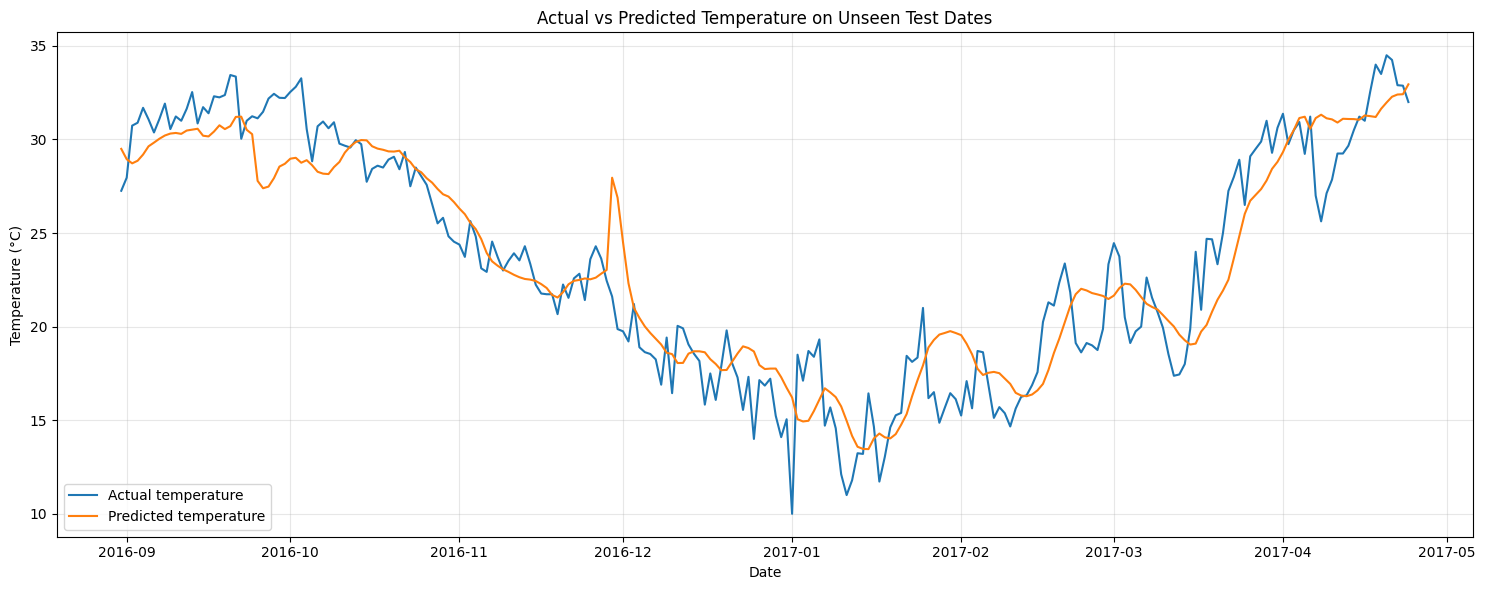

,date,actual_temperature,predicted_temperature
0,2016-08-31,27.259260,29.498334
1,2016-09-01,27.959999,28.945658
2,2016-09-02,30.739130,28.724078
3,2016-09-03,30.894737,28.864128
4,2016-09-04,31.692308,29.194699
5,2016-09-05,31.076924,29.634121
6,2016-09-06,30.375000,29.833187
7,2016-09-07,31.100001,30.040679
8,2016-09-08,31.916666,30.212717
9,2016-09-09,30.555555,30.316093


In [24]:
results = pd.DataFrame({
    "date": test_dates,
    "actual_temperature": y_actual,
    "predicted_temperature": y_pred
})

plt.figure(figsize=(15, 6))
plt.plot(
    results["date"],
    results["actual_temperature"],
    label="Actual temperature"
)
plt.plot(
    results["date"],
    results["predicted_temperature"],
    label="Predicted temperature"
)
plt.title("Actual vs Predicted Temperature on Unseen Test Dates")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(results.head(10))

In [25]:
test_positions = positions[test_mask]

baseline_pred = df["meantemp"].to_numpy()[test_positions - 1]

baseline_mae = mean_absolute_error(y_actual, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_actual, baseline_pred)
)

display(pd.DataFrame({
    "Model": ["Previous-day baseline", "LSTM"],
    "MAE (°C)": [baseline_mae, mae],
    "RMSE (°C)": [baseline_rmse, rmse]
}).round(4))

,Model,MAE (°C),RMSE (°C)
0,Previous-day baseline,1.1758,1.6080
1,LSTM,1.8378,2.2934


In [26]:
FORECAST_DAYS = 7

window = scaled_values[-LOOKBACK:].copy()
last_features = scaled_values[-1].copy()

forecast_values = []

for _ in range(FORECAST_DAYS):
    next_scaled_temp = float(
        model.predict(window[np.newaxis, :, :], verbose=0)[0, 0]
    )

    next_temp = next_scaled_temp * target_scale + target_mean
    forecast_values.append(next_temp)

    next_row = last_features.copy()
    next_row[target_idx] = next_scaled_temp

    window = np.vstack([window[1:], next_row])

future_dates = pd.date_range(
    df["date"].iloc[-1] + pd.Timedelta(days=1),
    periods=FORECAST_DAYS
)

future_df = pd.DataFrame({
    "date": future_dates,
    "forecast_temperature": forecast_values
})

display(future_df.round(2))

,date,forecast_temperature
0,2017-04-25,32.93
1,2017-04-26,33.02
2,2017-04-27,33.24
3,2017-04-28,33.40
4,2017-04-29,33.49
5,2017-04-30,33.52
6,2017-05-01,33.57


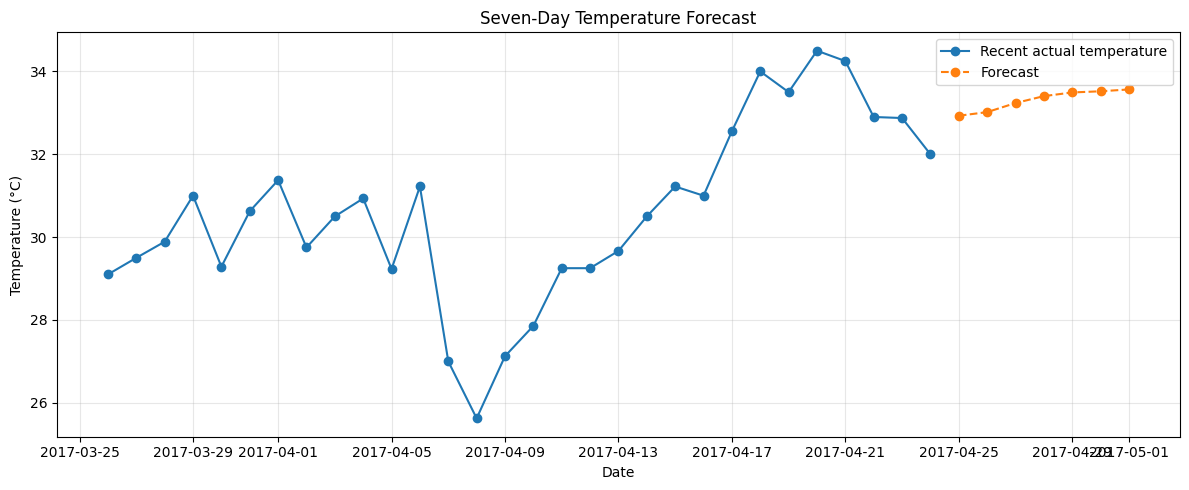

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["date"].iloc[-30:],
    df["meantemp"].iloc[-30:],
    marker="o",
    label="Recent actual temperature"
)

plt.plot(
    future_df["date"],
    future_df["forecast_temperature"],
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.title("Seven-Day Temperature Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
import json
import os

In [21]:
os.makedirs("climate_forecasting_project", exist_ok=True)

out = "climate_forecasting_project"

model.save(f"{out}/temperature_lstm.keras")

with open(f"{out}/preprocessing_config.json", "w") as f:
    json.dump({
        "features": feature_cols,
        "target": target_col,
        "lookback": LOOKBACK,
        "scaler_mean": scaler.mean_.tolist(),
        "scaler_scale": scaler.scale_.tolist()
    }, f, indent=2)

results.to_csv(f"{out}/test_predictions.csv", index=False)
future_df.to_csv(f"{out}/future_forecast.csv", index=False)
df.to_csv(f"{out}/cleaned_climate_data.csv", index=False)

with open(f"{out}/evaluation_metrics.json", "w") as f:
    json.dump({
        "MAE_Celsius": float(mae),
        "RMSE_Celsius": float(rmse),
        "R2": float(r2),
        "Baseline_MAE_Celsius": float(baseline_mae),
        "Baseline_RMSE_Celsius": float(baseline_rmse)
    }, f, indent=2)

print(os.listdir(out))

['future_forecast.csv', 'evaluation_metrics.json', 'temperature_lstm.keras', 'preprocessing_config.json', 'cleaned_climate_data.csv', 'test_predictions.csv']


In [22]:
import shutil

zip_path = shutil.make_archive(
    "climate_forecasting_project",
    "zip",
    root_dir="climate_forecasting_project"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>